# Fig 2a and Fig 2c: paper versions

Two separate figures:
- **Fig 2a, processor power** (`figures/fig2a_paper.*`), from `Data/generated/processors_clean.csv`. **Run `fig2a_processor_power.ipynb` first**; it builds that file.
- **Fig 2c, rack power** (`figures/fig2c_paper.*`), from `Data/generated/racks.csv`, AI and HPC systems only.

**Style:** plotly, matching the figures in `JevonsParadox/Rebound-Effect/rebound_effect_in_computation.ipynb`:
- Helvetica, black text, 550×500 px exported at 2× (PNG + PDF)
- black frame, faint grey gridlines
- axis titles with the unit on a second line in brackets
- **purple** for CPU-type points: server CPUs in 2a, HPC systems in 2c
- **green** for data-center GPUs and other AI accelerators (one series in 2a) and AI systems (2c)

Both figures use x = 2000 to 2030. Rack systems are plotted at mid-year.

**Labels are set by hand in two tables, `A_LABELS` (Fig 2a) and `C_LABELS` (Fig 2c).**
- Each entry is `(label text, ax, ay)`: the text's offset in pixels from its point (+ax right, +ay down). Use `<br>` for a line break. Edit these numbers to move a label.
- Each label has a short arrow whose head lands on its marker, as in the Rebound-Effect figures.
- The starting positions came from an automatic placement routine that avoids markers, labels and arrows. It's kept in the "Optional" cell at the end and is switched off by default (`RUN_AUTO_PLACEMENT = False`). Turn it on only to get fresh suggestions after changing the data.

**Legend:** outside the plot, top centre. **Axis titles:** single line.

The earlier matplotlib versions are kept at the end of the notebook (`*_mpl` outputs).

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MultipleLocator
from pathlib import Path
import paper_style as ps

ps.apply()
DATA = Path('../Data')
OUT = Path('../figures'); OUT.mkdir(exist_ok=True)
FIG_SIZE = (ps.COL_W, 2.7)
LABEL_FS = 5
X_START, X_END = 2000, 2028   # both figures

def top_legend(ax, handles, ncol):
    ax.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=ncol, frameon=False,
              handletextpad=0.3, columnspacing=1.0, borderaxespad=0.3)

def leader(ax, xy, xytext, text, ha='left'):
    ax.annotate(text, xy=xy, xytext=xytext, fontsize=LABEL_FS, color=ps.TEXT, va='center', ha=ha,
                arrowprops=dict(arrowstyle='-', color=ps.TEXT_2, lw=0.4, shrinkA=1, shrinkB=2))

def offset_label(ax, xy, text, dx, dy, ha):
    ax.annotate(text, xy=xy, xytext=(dx, dy), textcoords='offset points', fontsize=LABEL_FS,
                color=ps.TEXT, va='center', ha=ha)

def save(fig, name):
    fig.savefig(OUT / f'{name}.pdf')
    fig.savefig(OUT / f'{name}.png', dpi=600)
    fig.savefig(OUT / f'{name}.svg')

def short_leader(ax, xy, text, dx, dy, ha='right'):
    """Label offset (dx, dy) points from the point, joined by a short leader line."""
    ax.annotate(text, xy=xy, xytext=(dx, dy), textcoords='offset points', fontsize=LABEL_FS, color=ps.TEXT,
                va='center', ha=ha, arrowprops=dict(arrowstyle='-', color=ps.TEXT_2, lw=0.35, shrinkA=0.5, shrinkB=1.5))

## Data

In [ ]:
procs = pd.read_csv(DATA / 'generated/processors_clean.csv', parse_dates=['date'])

racks = pd.read_csv(DATA / 'generated/racks.csv', dtype=str)
racks['kW'] = pd.to_numeric(racks['rack_kW'].str.lstrip('~'), errors='coerce')
racks['year'] = racks['year'].astype(int)
racks['x'] = racks['year'] + 0.5   # mid-year, on the same 2000-2027 axis as the dated processors

# Left off Fig 2c: low-confidence values, and Catalina (a GB200 NVL72 variant, duplicates that point)
EXCLUDE_RACKS = ['AMD Helios (MI400 series)', 'Huawei CloudMatrix 384', 'NVIDIA DGX-2 (V100)', 'Meta Catalina (GB200)',
                 'xAI Colossus (phase 1)']   # Colossus: low confidence (per-rack power unpublished); see racks.csv notes
rack_pts = racks[racks['category'].isin(['ai_accelerator', 'hpc']) & racks['kW'].notna()
                 & ~racks['system'].isin(EXCLUDE_RACKS) & (racks['x'] < X_END)].copy()
outside = racks[racks['category'].isin(['ai_accelerator', 'hpc']) & racks['kW'].notna() & (racks['x'] >= X_END)]
print('Not shown (beyond the x-axis):', outside['system'].tolist())
rack_pts[['system', 'year', 'kW', 'category', 'status']].sort_values('year')

Not shown (beyond the x-axis): []


,system,year,kW,category,status
12,IBM BlueGene/L (LLNL),2005,22.0,hpc,shipped
13,Cray XT5 Jaguar (ORNL),2009,35.0,hpc,shipped
14,IBM BlueGene/Q Sequoia (LLNL),2012,82.0,hpc,shipped
15,Cray XK7 Titan (ORNL),2012,41.0,hpc,shipped
27,NVIDIA DGX-1 (P100),2016,29.0,ai_accelerator,shipped
17,IBM Summit AC922 (ORNL),2018,39.0,hpc,shipped
18,Fujitsu Fugaku (RIKEN),2020,69.0,hpc,shipped
29,NVIDIA DGX A100 SuperPOD,2020,26.0,ai_accelerator,shipped
19,HPE Cray EX Frontier (ORNL),2022,285.0,hpc,shipped
30,NVIDIA DGX H100 SuperPOD,2023,41.0,ai_accelerator,shipped


## Plotly style (and the label-placement helpers used by the optional cell at the end)

In [ ]:
import numpy as np
import plotly.graph_objects as go

# --- Style from the Rebound-Effect notebook ---
FONT_FAMILY = 'Helvetica'
PURPLE = {'marker': 'purple', 'text': '#3f2a69'}     # CPU-type: server CPUs (2a), HPC systems (2c)
GREEN = {'marker': '#6a994e', 'text': '#42512a'}     # AI accelerators / GPUs (2a), AI systems (2c)
GRID_MAJOR, GRID_MINOR = '#E3E3E3', '#F5F5F5'
W_PX, H_PX = 566, 528                     # reference 550x500; +16 px wide so the '2030' tick label fits, +28 px tall for the legend band
MARGIN = dict(l=92, r=28, t=40, b=78)                # fixed (no automargin); plot area is the same size as before the legend moved out
AXIS_TITLE_PX, TICK_PX, LABEL_PX, LEGEND_PX = 19, 15, 12, 13

def base_layout(fig, xtitle, ytitle, xrange, yrange, xdtick, ydtick):
    axis = dict(showgrid=True, gridcolor=GRID_MAJOR, gridwidth=1, zeroline=False, showline=False, ticks='',
                tickfont=dict(size=TICK_PX), automargin=False, minor=dict(showgrid=True, gridcolor=GRID_MINOR))
    fig.update_layout(
        width=W_PX, height=H_PX, margin=MARGIN, plot_bgcolor='white', paper_bgcolor='white',
        font=dict(family=FONT_FAMILY, size=12, color='black'),
        xaxis=dict(range=xrange, dtick=xdtick, title=dict(text=xtitle, standoff=10, font=dict(size=AXIS_TITLE_PX)),
                   minor_dtick=xdtick / 5 if xdtick >= 5 else None, **axis),
        yaxis=dict(range=yrange, dtick=ydtick, tickformat=',', title=dict(text=ytitle, standoff=5, font=dict(size=AXIS_TITLE_PX)),
                   minor_dtick=ydtick / 2, **axis),
        legend=dict(orientation='h', x=0.5, xanchor='center', y=1.01, yanchor='bottom', font=dict(size=LEGEND_PX),
                    bgcolor='rgba(0,0,0,0)',
                    itemsizing='constant'),   # outside the plot, top centre
        shapes=[dict(type='rect', x0=0, x1=1, y0=0, y1=1, xref='paper', yref='paper', line=dict(color='black', width=2))],
    )

def export(fig, name):
    fig.write_image(OUT / f'{name}.png', scale=2)
    fig.write_image(OUT / f'{name}.pdf', scale=2)
    fig.write_html(OUT / f'{name}.html', include_plotlyjs='cdn')

# --- Automatic label placement (pixel geometry) ---
PLOT_W = W_PX - MARGIN['l'] - MARGIN['r']
PLOT_H = H_PX - MARGIN['t'] - MARGIN['b']

def to_px(x, y, xr, yr):
    """Data -> pixel coordinates within the plot area (y grows downward)."""
    px = (np.asarray(x, float) - xr[0]) / (xr[1] - xr[0]) * PLOT_W
    py = (1 - (np.asarray(y, float) - yr[0]) / (yr[1] - yr[0])) * PLOT_H
    return px, py

def text_box(text, font_px, cx, cy, pad=1.5):
    lines = text.split('<br>')
    w = max(len(l) for l in lines) * font_px * 0.56 + 2 * pad
    h = len(lines) * font_px * 1.15 + 2 * pad
    return (cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2)

def box_hits_circle(b, cx, cy, r):
    nx, ny = min(max(cx, b[0]), b[2]), min(max(cy, b[1]), b[3])
    return (nx - cx) ** 2 + (ny - cy) ** 2 < r ** 2

def boxes_overlap(a, b, gap=1.5):
    return not (a[2] + gap < b[0] or b[2] + gap < a[0] or a[3] + gap < b[1] or b[3] + gap < a[1])

def candidate_offsets(min_d, max_d, step):
    """(dx, dy) offsets ordered by distance; at equal distance, closer-to-vertical first (up before down)."""
    out = []
    for d in range(min_d, max_d + 1, step):
        for a in range(0, 360, 15):                       # 90 = up
            t = np.radians(a)
            pref = min(abs(a - 90), abs(a - 270)) + (0 if a < 180 else 1)
            out.append((d, pref, d * np.cos(t), -d * np.sin(t)))
    return [(dx, dy) for _, _, dx, dy in sorted(out)]

def _seg_intersect(p1, p2, p3, p4):
    def orient(a, b, c):
        return (b[0] - a[0]) * (c[1] - a[1]) - (b[1] - a[1]) * (c[0] - a[0])
    d1, d2 = orient(p3, p4, p1), orient(p3, p4, p2)
    d3, d4 = orient(p1, p2, p3), orient(p1, p2, p4)
    return (d1 * d2 < 0) and (d3 * d4 < 0)

def _in_box(x, y, b, pad=0.0):
    return b[0] - pad <= x <= b[2] + pad and b[1] - pad <= y <= b[3] + pad

ASSOC_MARGIN = 6   # px: a label must be this much closer to its own marker than to any other

def place_labels(targets, obstacles, r_obstacle, font_px, offsets, arrow, reserved=(), assoc=False):
    """Greedy label placement in pixel space.
    targets: dicts with px, py, variants (label texts, preferred first). obstacles: (N, 2) marker pixel positions.
    A candidate is rejected if its text box touches any marker, another label or the reserved areas, or (arrow=True)
    if its arrow crosses a marker, another label or another arrow.
    If no clean arrow exists, falls back to the candidate whose arrow crosses the fewest markers (reported).
    Returns (text, dx, dy, n_markers_crossed) or None per target."""
    boxes, segs, results = list(reserved), [], []
    for t in targets:
        p0 = (t['px'], t['py'])
        best, fallback = None, None
        for text in t['variants']:
            for dx, dy in offsets(text):
                cx, cy = t['px'] + dx, t['py'] + dy
                b = text_box(text, font_px, cx, cy)
                if b[0] < 2 or b[2] > PLOT_W - 2 or b[1] < 2 or b[3] > PLOT_H - 2:
                    continue
                if any(box_hits_circle(b, ox, oy, r_obstacle + 1) for ox, oy in obstacles):
                    continue
                if any(boxes_overlap(b, q) for q in boxes):
                    continue
                if assoc:   # without arrows, the label must sit closer to its own marker than to any other
                    nx = np.clip(obstacles[:, 0], b[0], b[2]); ny = np.clip(obstacles[:, 1], b[1], b[3])
                    d = np.hypot(obstacles[:, 0] - nx, obstacles[:, 1] - ny)
                    own = np.hypot(t['px'] - min(max(t['px'], b[0]), b[2]), t['py'] - min(max(t['py'], b[1]), b[3]))
                    others = d[np.hypot(obstacles[:, 0] - t['px'], obstacles[:, 1] - t['py']) > 1]
                    if len(others) and own + ASSOC_MARGIN > others.min():
                        continue
                crossed = 0
                if arrow:
                    # arrow runs from the point to where it meets the text box
                    pts = [(t['px'] + dx * s, t['py'] + dy * s) for s in np.linspace(0, 1, 60)]
                    pts = [(x, y) for x, y in pts if not _in_box(x, y, b) and np.hypot(x - p0[0], y - p0[1]) >= r_obstacle + 2]
                    if not pts:
                        continue
                    seg = (p0, pts[-1])
                    if any(_in_box(x, y, q, 1) for x, y in pts for q in boxes):
                        continue
                    if any(_seg_intersect(seg[0], seg[1], s[0], s[1]) for s in segs):
                        continue
                    if any(_in_box(x, y, b, 1) for s in segs for x, y in
                           [(s[0][0] + (s[1][0] - s[0][0]) * u, s[0][1] + (s[1][1] - s[0][1]) * u) for u in np.linspace(0, 1, 30)]):
                        continue
                    hit = np.zeros(len(obstacles), bool)
                    for x, y in pts:
                        hit |= np.hypot(obstacles[:, 0] - x, obstacles[:, 1] - y) < r_obstacle + 0.5
                    crossed = int(hit.sum())
                    if crossed:
                        if fallback is None or crossed < fallback[3]:
                            fallback = (text, dx, dy, crossed, b, seg)
                        continue
                    best = (text, dx, dy, 0, b, seg)
                else:
                    best = (text, dx, dy, 0, b, None)
                break
            if best:
                break
        choice = best or fallback
        if choice:
            boxes.append(choice[4])
            if choice[5]:
                segs.append(choice[5])
            results.append(choice[:4])
        else:
            results.append(None)
    return results

def place_labels_best(targets, *args, tries=300, seed=0, **kw):
    """Run place_labels over many target orders; keep the result with the most labels placed cleanly,
    then the fewest marker crossings, then the shortest total offset. Returns results in the input order."""
    rng = np.random.default_rng(seed)
    best_key, best = None, None
    orders = [list(range(len(targets)))] + [list(rng.permutation(len(targets))) for _ in range(tries)]
    for order in orders:
        res = place_labels([targets[i] for i in order], *args, **kw)
        placed = [r for r in res if r]
        key = (-len(placed), sum(r[3] for r in placed), sum(np.hypot(r[1], r[2]) for r in placed))
        if best_key is None or key < best_key:
            best_key, best = key, [None] * len(targets)
            for i, r in zip(order, res):
                best[i] = r
    return best

def legend_box(labels, font_px, marker_px=14):
    """Approximate pixel box of the top-centre horizontal legend, reserved so labels avoid it."""
    w = sum(len(l) * font_px * 0.56 + marker_px + 28 for l in labels)
    h = font_px * 1.6 + 6
    return ((PLOT_W - w) / 2, 2, (PLOT_W + w) / 2, 2 + h)

## Fig 2a: processor power (plotly)

In [ ]:
X_RANGE, Y_RANGE_A = [2000, 2030], [0, 1500]   # x shared by 2a and 2c
MARKER_A = 7                                 # 645 points: smaller than the reference's 11 so the cloud stays readable
SERIES = {  # legend name -> (kinds in processors_clean.csv, colours); GPUs and other AI accelerators share one series
    'Server CPUs': (['Server CPU'], PURPLE),
    'Data-center GPUs / AI accelerators': (['Data-center GPU', 'Other AI accelerator'], GREEN),
}
A_LABELS = {  # key -> (label text, ax, ay): text offset in px from the point; +ax right, +ay down. '<br>' = line break
    'NVIDIA GB300 (Blackwell Ultra)':  ('AMD MI355X, NVIDIA GB300', -60.6, 35),
    'Google TPU v7 Ironwood':          ('Google TPU v7', -67.6, -18.1),
    'Intel Habana Gaudi3':             ('Intel Gaudi 3', -54, -0),
    'AMD Instinct MI300X':             ('AMD MI300X', -4.7, -17.4),
    'NVIDIA H100 SXM5 80GB':           ('NVIDIA H100', -44.4, -11.9),
    'Intel Xeon 6980P':                ('Intel Xeon 6980P', -98.5, -26.4),
    'Google TPU v3':                   ('Google TPU v3', 0, -18),
    'NVIDIA Tesla K80':                ('NVIDIA K80', 11, -19.1),
}

procs['year_frac'] = procs['date'].dt.year + (procs['date'].dt.dayofyear - 1) / 365.25
fa = go.Figure()
for name, (kinds, col) in SERIES.items():
    d = procs[procs['kind'].isin(kinds)]
    fa.add_trace(go.Scatter(x=d['year_frac'], y=d['tdp_W'], mode='markers', name=name, hovertext=d['product'],
                            marker=dict(color=col['marker'], size=MARKER_A, symbol='circle', opacity=0.75, line=dict(width=0))))
for product, (text, ax, ay) in A_LABELS.items():
    r = procs[procs['product'] == product].iloc[0]
    col = PURPLE if r['kind'] == 'Server CPU' else GREEN
    fa.add_annotation(x=r['year_frac'], y=r['tdp_W'], text=text, showarrow=True, arrowhead=2, arrowsize=0.8,
                      arrowwidth=1, arrowcolor=col['marker'], ax=ax, ay=ay, font=dict(size=LABEL_PX, color=col['text']))

base_layout(fa, 'Release year', 'Processor power (TDP) [W]', X_RANGE, Y_RANGE_A, 5, 300)
export(fa, 'fig2a_paper')
fa.show()

## Fig 2c: rack power (plotly)

In [ ]:
Y_RANGE_C = [0, 650]
MARKER_C = 9                                 # reference uses 11; 9 leaves room for labels in the crowded 2016-2026 corner
LABEL_PX_C = 10                              # a little smaller than 2a: the 2016-2026 / 0-150 kW corner is crowded
GROUP_STYLE = {'ai_accelerator': ('AI systems', GREEN, 'circle'), 'hpc': ('HPC systems', PURPLE, 'square')}
# GB200 and GB300 NVL72 nearly coincide, so one label ('NVIDIA GB200, GB300') points at the GB200 marker
C_LABELS = {  # key -> (label text, ax, ay): text offset in px from the point; +ax right, +ay down. '<br>' = line break
    'IBM BlueGene/L (LLNL)':             ('BlueGene/L', -38.5, -6.2),
    'Cray XT5 Jaguar (ORNL)':            ('Jaguar', -27.3, -6.2),
    'IBM BlueGene/Q Sequoia (LLNL)':     ('Sequoia', -28.1, -6.2),
    'Cray XK7 Titan (ORNL)':             ('Titan', -0.5, 15.8),
    'NVIDIA DGX-1 (P100)':               ('DGX-1', -24.5, -6.2),
    'IBM Summit AC922 (ORNL)':           ('Summit', -1.3, -14.2),
    'Fujitsu Fugaku (RIKEN)':            ('Fugaku', 0.7, -14.2),
    'NVIDIA DGX A100 SuperPOD':          ('DGX<br>A100', 20.3, 0),
    'HPE Cray EX Frontier (ORNL)':       ('Frontier', -30.9, -6.2),
    'HPE Cray EX Aurora (ANL)':          ('Aurora', -27.3, -6.2),
    'Tesla Dojo ExaPOD cabinet':         ('Tesla Dojo', -38.5, -0.2),
    'NVIDIA DGX H100 SuperPOD':          ('DGX H100', -6.9, -14.2),
    'HPE Cray EX El Capitan (LLNL)':     ('El Capitan', -38.5, -6.2),
    'NVIDIA DGX B200':                   ('DGX<br>B200', 20.3, 2),
    'NVIDIA GB200 NVL72':                ('NVIDIA GB200, GB300', -61.7, -6.2),
    'AMD Instinct MI355X platform':      ('AMD MI355X', -18.5, -32),
    'Google TPU v7 Ironwood superpod':   ('Google TPU v7', -4.1, -15.5),
    'NVIDIA Vera Rubin NVL72':           ('NVIDIA<br>Vera Rubin NVL72', -29.8, -111.1),
    'NVIDIA Rubin Ultra NVL576 (Kyber)': ('NVIDIA Kyber NVL576', -49.7, 15.8),
}

fc = go.Figure()
for cat, (name, col, symbol) in GROUP_STYLE.items():
    d = rack_pts[rack_pts['category'] == cat]
    hollow = (d['status'] == 'announced').tolist()
    fc.add_trace(go.Scatter(
        x=d['x'], y=d['kW'], mode='markers', name=name, hovertext=d['system'],
        marker=dict(size=MARKER_C, symbol=symbol, opacity=0.9,
                    color=['white' if h else col['marker'] for h in hollow],
                    line=dict(width=[2 if h else 0 for h in hollow], color=col['marker']))))
if (rack_pts['status'] == 'announced').any():   # legend entry for hollow = announced
    fc.add_trace(go.Scatter(x=[None], y=[None], mode='markers', name='Announced',
                            marker=dict(size=MARKER_C, color='white', line=dict(width=2, color='#555555'))))

# Short arrows whose head lands on the marker (Rebound-Effect style), so each label clearly belongs to its point
for system, (text, ax, ay) in C_LABELS.items():
    r = rack_pts[rack_pts['system'] == system]
    if r.empty:
        continue
    r = r.iloc[0]
    col = GROUP_STYLE[r['category']][1]
    fc.add_annotation(x=r['x'], y=r['kW'], text=text, showarrow=True, arrowhead=2, arrowsize=0.8, arrowwidth=1,
                      arrowcolor=col['marker'], ax=ax, ay=ay, font=dict(size=LABEL_PX_C, color=col['text']))

base_layout(fc, 'Year', 'Rack / cabinet power [kW]', X_RANGE, Y_RANGE_C, 5, 100)
export(fc, 'fig2c_paper')
fc.show()

## Fig 2c, 0–400 kW version (plotly)

Same data and style with the y-axis capped at 400 kW for readability. Kyber NVL576 (600 kW, announced for 2027) is left out and covered in the text, so there's no 'Announced' legend entry. Output: `figures/fig2c_paper_0to400.*` (the 0–650 kW figure is unchanged).

In [ ]:
Y_RANGE_C400 = [0, 400]
EXCLUDE_400 = ['NVIDIA Rubin Ultra NVL576 (Kyber)']   # 600 kW, announced for 2027: mentioned in the text instead
rack_400 = rack_pts[~rack_pts['system'].isin(EXCLUDE_400)]
# Positions for this version only (the 0-400 kW scale leaves more room, so most labels sit just above their point)
C_LABELS_400 = {  # key -> (label text, ax, ay): text offset in px from the point; +ax right, +ay down. '<br>' = line break
    'IBM BlueGene/L (LLNL)':               ('BlueGene/L', 0, -13),
    'Cray XT5 Jaguar (ORNL)':              ('Jaguar', 0, -13),
    'IBM BlueGene/Q Sequoia (LLNL)':       ('Sequoia', 0, -13),
    'Cray XK7 Titan (ORNL)':               ('Titan', 0, -13),
    'NVIDIA DGX-1 (P100)':                 ('NVIDIA DGX-1', 0, 13),
    'IBM Summit AC922 (ORNL)':             ('Summit', 0, -13),
    'Fujitsu Fugaku (RIKEN)':              ('Fugaku', 0, -13),
    'NVIDIA DGX A100 SuperPOD':            ('NVIDIA DGX A100', 24, 14),
    'HPE Cray EX Frontier (ORNL)':         ('Frontier', 0, -13),
    'HPE Cray EX Aurora (ANL)':            ('Aurora', 0, -14),
    'Tesla Dojo ExaPOD cabinet':           ('Tesla Dojo', 0, -13),
    'NVIDIA DGX H100 SuperPOD':            ('NVIDIA DGX H100', -8, -14),
    'HPE Cray EX El Capitan (LLNL)':       ('El Capitan', 0, -13),
    'NVIDIA DGX B200':                     ('DGX<br>B200', 23, 6),
    'NVIDIA GB200 NVL72':                  ('NVIDIA GB200', -44, 0),
    'NVIDIA GB300 NVL72':                  ('NVIDIA GB300', 0, -13),
    'AMD Instinct MI355X platform':        ('AMD MI355X', 0, 13),
    'Google TPU v7 Ironwood superpod':     ('Google TPU v7', 0, -13),
    'NVIDIA Vera Rubin NVL72':             ('NVIDIA<br>Vera Rubin NVL72', 4, -18),
}

f4 = go.Figure()
for cat, (name, col, symbol) in GROUP_STYLE.items():
    d = rack_400[rack_400['category'] == cat]
    f4.add_trace(go.Scatter(x=d['x'], y=d['kW'], mode='markers', name=name, hovertext=d['system'],
                            marker=dict(size=MARKER_C, symbol=symbol, opacity=0.7, color=col['marker'], line=dict(width=0))))
for system, (text, ax, ay) in C_LABELS_400.items():
    r = rack_400[rack_400['system'] == system]
    if r.empty:
        continue
    r = r.iloc[0]
    col = GROUP_STYLE[r['category']][1]
    f4.add_annotation(x=r['x'], y=r['kW'], text=text, showarrow=True, arrowhead=2, arrowsize=0.8, arrowwidth=1,
                      arrowcolor=col['marker'], ax=ax, ay=ay, font=dict(size=LABEL_PX_C, color=col['text']))

base_layout(f4, 'Year', 'Rack / cabinet power [kW]', X_RANGE, Y_RANGE_C400, 5, 100)
export(f4, 'fig2c_paper_0to400')
f4.show()

## Optional: re-run automatic label placement (off by default)

In [ ]:
# Optional: automatic label placement, to get fresh suggestions for A_LABELS / C_LABELS (e.g. after the data change).
# It prints suggested tables to paste above; it does not change the figures. Takes ~1 min.
RUN_AUTO_PLACEMENT = False

if RUN_AUTO_PLACEMENT:
    def suggest(points_x, points_y, xr, yr, labels, marker_px, font_px, offsets, arrow, assoc):
        ox, oy = to_px(points_x, points_y, xr, yr)
        obst = np.column_stack([ox, oy])
        targets = []
        for key, (px_, py_, variants) in labels.items():
            px, py = to_px(px_, py_, xr, yr)
            targets.append(dict(px=float(px), py=float(py), variants=variants, key=key))
        res = place_labels_best(targets, obst, marker_px / 2 + 0.5, font_px, offsets=offsets, arrow=arrow, assoc=assoc, tries=100)
        for t, p in zip(targets, res):
            print(f"    {t['key']!r}: " + (f"({p[0]!r}, {p[1]:.0f}, {p[2]:.0f})," if p else "None,  # could not place"))

    print('A_LABELS suggestions:')
    lab = {k: (procs.loc[procs['product'] == k, 'year_frac'].iloc[0], procs.loc[procs['product'] == k, 'tdp_W'].iloc[0], [v[0]])
           for k, v in A_LABELS.items()}
    suggest(procs['year_frac'], procs['tdp_W'], X_RANGE, Y_RANGE_A, lab, MARKER_A, LABEL_PX,
            lambda text: candidate_offsets(14, 240, 4), arrow=True, assoc=False)
    print('C_LABELS suggestions:')
    lab = {k: (rack_pts.loc[rack_pts['system'] == k, 'x'].iloc[0], rack_pts.loc[rack_pts['system'] == k, 'kW'].iloc[0], [v[0]])
           for k, v in C_LABELS.items() if (rack_pts['system'] == k).any()}
    suggest(rack_pts['x'], rack_pts['kW'], X_RANGE, Y_RANGE_C, lab, MARKER_C, LABEL_PX_C,
            lambda text: candidate_offsets(14, 120, 3), arrow=True, assoc=False)

## Previous matplotlib versions (kept for reference; outputs `*_mpl`)

## Fig 2a: processor power

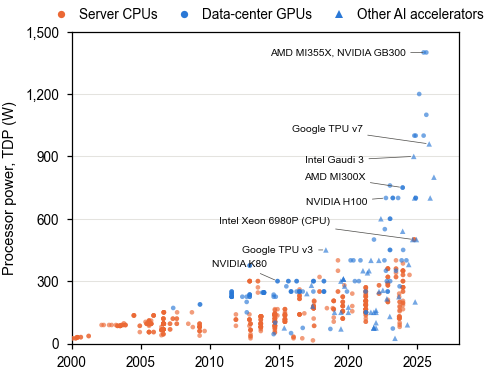

In [ ]:
KIND = {  # kind -> (legend label, colour, marker, size)
    'Server CPU': ('Server CPUs', ps.C_GP, 'o', 5),
    'Data-center GPU': ('Data-center GPUs', ps.C_AI, 'o', 5),
    'Other AI accelerator': ('Other AI accelerators', ps.C_AI, '^', 7),
}
# Labels sit just left of their point with a short leader; offsets (dx, dy) in points, tuned by eye
PROC_LABELS = {  # product -> (label, dx, dy)
    'NVIDIA GB300 (Blackwell Ultra)': ('AMD MI355X, NVIDIA GB300', -10, 0),
    'Google TPU v7 Ironwood': ('Google TPU v7', -32, 7),
    'Intel Habana Gaudi3': ('Intel Gaudi 3', -24, -2),
    'AMD Instinct MI300X': ('AMD MI300X', -18, 5),
    'NVIDIA H100 SXM5 80GB': ('NVIDIA H100', -9, -2),
    'Intel Xeon 6980P': ('Intel Xeon 6980P (CPU)', -40, 9),
    'Google TPU v3': ('Google TPU v3', -6, 0),
    'NVIDIA Tesla K80': ('NVIDIA K80', -5, 8),
}

fig, ax = plt.subplots(figsize=FIG_SIZE)
for kind, (name, color, marker, size) in KIND.items():
    d = procs[procs['kind'] == kind]
    ax.scatter(d['date'], d['tdp_W'], s=size, marker=marker, color=color, alpha=0.65, edgecolor='none', zorder=3)
for product, (text, dx, dy) in PROC_LABELS.items():
    row = procs[procs['product'] == product]
    short_leader(ax, (row['date'].iloc[0], row['tdp_W'].iloc[0]), text, dx, dy)

ax.set_xlim(pd.Timestamp(f'{X_START}-01-01'), pd.Timestamp(f'{X_END}-01-01'))
ax.xaxis.set_major_locator(mdates.YearLocator(5, month=1, day=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_ylim(0, 1500)
ax.yaxis.set_major_locator(MultipleLocator(300))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_ylabel('Processor power, TDP (W)')
handles = [Line2D([], [], ls='', marker=m, ms=3.5 if m == 'o' else 4, mfc=c, mec='none', label=l)
           for l, c, m, _ in KIND.values()]
top_legend(ax, handles, ncol=3)
save(fig, 'fig2a_paper_mpl')
plt.show()

## Fig 2c: rack power

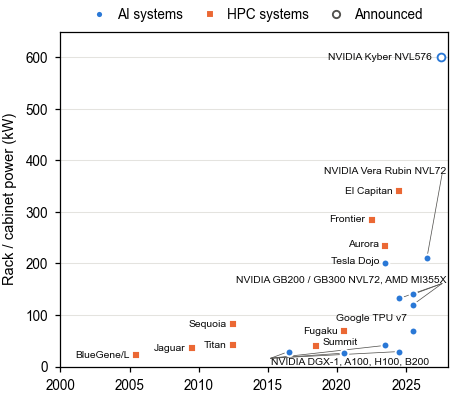

In [ ]:
GROUP = {'ai_accelerator': ('AI systems', ps.C_AI, 'o'), 'hpc': ('HPC systems', ps.C_GP, 's')}
FIG_SIZE_C = (ps.COL_W, 2.9)

# Direct labels, offsets in points (label, dx, dy, ha)
RACK_DIRECT = {
    'NVIDIA Rubin Ultra NVL576 (Kyber)': ('NVIDIA Kyber NVL576', -4, 0, 'right'),
    'HPE Cray EX El Capitan (LLNL)': ('El Capitan', -3, 0, 'right'),
    'HPE Cray EX Frontier (ORNL)': ('Frontier', -3, 0, 'right'),
    'HPE Cray EX Aurora (ANL)': ('Aurora', -3, 1, 'right'),
    'Tesla Dojo ExaPOD cabinet': ('Tesla Dojo', -3, 1, 'right'),
    'Google TPU v7 Ironwood superpod': ('Google TPU v7', -3, 6, 'right'),
    'Fujitsu Fugaku (RIKEN)': ('Fugaku', -3, 0, 'right'),
    'IBM BlueGene/Q Sequoia (LLNL)': ('Sequoia', -3, 0, 'right'),
    'Cray XK7 Titan (ORNL)': ('Titan', -3, 0, 'right'),
    'Cray XT5 Jaguar (ORNL)': ('Jaguar', -3, 0, 'right'),
    'IBM BlueGene/L (LLNL)': ('BlueGene/L', -3, 0, 'right'),
    'IBM Summit AC922 (ORNL)': ('Summit', 3, 2, 'left'),
}
# Labels with leader lines: (label, text x, text y, ha, [systems])
RACK_LEADERS = [
    ('NVIDIA Vera Rubin NVL72', 2027.9, 380, 'right', ['NVIDIA Vera Rubin NVL72']),
    ('NVIDIA GB200 / GB300 NVL72, AMD MI355X', 2027.9, 168, 'right',
     ['NVIDIA GB200 NVL72', 'NVIDIA GB300 NVL72', 'AMD Instinct MI355X platform']),
    ('NVIDIA DGX-1, A100, H100, B200', 2015.2, 9, 'left',
     ['NVIDIA DGX-1 (P100)', 'NVIDIA DGX A100 SuperPOD', 'NVIDIA DGX H100 SuperPOD', 'NVIDIA DGX B200']),
]

fig, ax = plt.subplots(figsize=FIG_SIZE_C)
for _, r in rack_pts.iterrows():
    _, color, marker = GROUP[r['category']]
    hollow = r['status'] == 'announced'
    ax.scatter(r['x'], r['kW'], s=14, marker=marker, linewidth=0.9, zorder=4,
               facecolor='white' if hollow else color, edgecolor=color if hollow else 'white')
for system, (text, dx, dy, ha) in RACK_DIRECT.items():
    r = rack_pts[rack_pts['system'] == system]
    if len(r):
        offset_label(ax, (r['x'].iloc[0], r['kW'].iloc[0]), text, dx, dy, ha)
for text, tx, ty, ha, systems in RACK_LEADERS:
    ax.text(tx, ty, text, fontsize=LABEL_FS, color=ps.TEXT, va='center', ha=ha)
    anchor_y = ty - 7 if ty > 100 else ty + 7     # leave from the side of the text facing the points
    for system in systems:
        r = rack_pts[rack_pts['system'] == system]
        if len(r):
            ax.annotate('', xy=(r['x'].iloc[0], r['kW'].iloc[0]), xytext=(tx if ha == 'left' else tx - 0.3, anchor_y),
                        arrowprops=dict(arrowstyle='-', color=ps.TEXT_2, lw=0.35, shrinkA=0, shrinkB=2))

ax.set_xlim(X_START, X_END)
ax.set_xticks(range(X_START, X_END + 1, 5))
ax.set_ylim(0, 650)
ax.yaxis.set_major_locator(MultipleLocator(100))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_ylabel('Rack / cabinet power (kW)')
handles = [Line2D([], [], ls='', marker=m, ms=3.5, mfc=c, mec='white', label=l) for l, c, m in GROUP.values()]
if (rack_pts['status'] == 'announced').any():
    handles.append(Line2D([], [], ls='', marker='o', ms=3.5, mfc='white', mec=ps.TEXT_2, mew=0.9, label='Announced'))
top_legend(ax, handles, ncol=len(handles))
save(fig, 'fig2c_paper_mpl')
plt.show()